## IMPORTING LIBRARIES

In [9]:
import pandas as pd
import numpy as np
import os
from keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf
from keras.models import Model, Sequential, load_model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, BatchNormalization, GlobalAveragePooling2D,Activation,Input
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
! pip install seaborn
import seaborn as sns
import cv2


[notice] A new release of pip is available: 23.1.2 -> 23.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## DATA LOADING

In [10]:
data_dir=r"DATA"
cancer=[]
for file in os.listdir(data_dir):
    cancer+=[file]
print(cancer)
print(len(cancer))

['Colon_Adenocarcinoma', 'Colon_Benign_Tissue']
2


## PREPROCESSING

In [11]:
img_height,img_width=224,224
batch_size=20

In [12]:
train_datagen = ImageDataGenerator(rescale=1./255,validation_split=0.2)
train_generator = train_datagen.flow_from_directory(data_dir,
                                                target_size=(img_height,img_width),
                                                batch_size=batch_size,
                                                class_mode='categorical',
                                                subset='training')
test_generator = train_datagen.flow_from_directory(data_dir,
                                                target_size=(img_height,img_width),
                                                batch_size=batch_size,
                                                class_mode='categorical',
                                                subset='validation')

Found 5408 images belonging to 2 classes.
Found 1352 images belonging to 2 classes.


## APPLYING MOBILENET ALGORITHM:

In [13]:
base_model = tf.keras.applications.MobileNet(input_shape=(img_height,img_width, 3), include_top=False,
                          weights='imagenet')
model1 = Sequential()
model1.add(base_model)
model1.add(GlobalAveragePooling2D())
model1.add(Dense(64, activation='relu'))
model1.add(BatchNormalization())
model1.add(Dropout(0.2))
model1.add(Dense(2, activation='sigmoid'))
model1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenet_1.00_224 (Functio  (None, 7, 7, 1024)       3228864   
 nal)                                                            
                                                                 
 global_average_pooling2d (G  (None, 1024)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dense (Dense)               (None, 64)                65600     
                                                                 
 batch_normalization (BatchN  (None, 64)               256       
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                        

In [14]:
model1.compile(optimizer='Adam',loss="categorical_crossentropy",metrics=["accuracy"])
hist2=model1.fit_generator(train_generator,epochs=10,validation_data=test_generator,verbose=1)

C:\Users\0618\AppData\Local\Temp\ipykernel_3392\2070720287.py:2: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  hist2=model1.fit_generator(train_generator,epochs=10,validation_data=test_generator,verbose=1)


Epoch 1/10
271/271 [==============================] - 574s 2s/step - loss: 0.0906 - accuracy: 0.9719 - val_loss: 0.0032 - val_accuracy: 0.9993
Epoch 2/10
271/271 [==============================] - 539s 2s/step - loss: 0.0643 - accuracy: 0.9826 - val_loss: 0.0055 - val_accuracy: 0.9985
Epoch 3/10
271/271 [==============================] - 543s 2s/step - loss: 0.0233 - accuracy: 0.9956 - val_loss: 0.0017 - val_accuracy: 0.9993
Epoch 4/10
271/271 [==============================] - 574s 2s/step - loss: 0.0307 - accuracy: 0.9913 - val_loss: 0.0042 - val_accuracy: 0.9993
Epoch 5/10
271/271 [==============================] - 560s 2s/step - loss: 0.0113 - accuracy: 0.9970 - val_loss: 6.3234e-04 - val_accuracy: 1.0000
Epoch 6/10
271/271 [==============================] - 559s 2s/step - loss: 0.0158 - accuracy: 0.9945 - val_loss: 0.0029 - val_accuracy: 0.9993
Epoch 7/10
271/271 [==============================] - 540s 2s/step - loss: 0.0095 - accuracy: 0.9972 - val_loss: 9.6461e-04 - val_accuracy

## GRAPH:

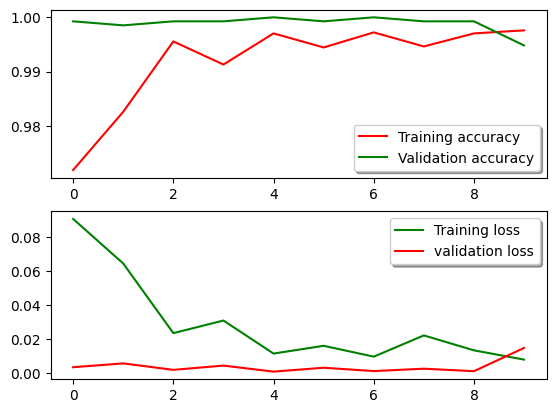

In [16]:
fig, ax = plt.subplots(2,1)
ax[0].plot(hist2.history['accuracy'], color='r', label="Training accuracy")
ax[0].plot(hist2.history['val_accuracy'], color='g',label="Validation accuracy")
legend = ax[0].legend(loc='best', shadow=True)

ax[1].plot(hist2.history['loss'], color='g', label="Training loss")
ax[1].plot(hist2.history['val_loss'], color='r', label="validation loss",axes =ax[1])
legend = ax[1].legend(loc='best', shadow=True)

In [18]:
model1.evaluate(test_generator)
model1.save("mobilenet.h5")

68/68 [==============================] - 25s 364ms/step - loss: 0.0146 - accuracy: 0.9948
